In [8]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import mean_squared_error
import numpy as np
import mlflow.sklearn

# Set an experiment name
mlflow.set_experiment("spider_mite_prediction")

# Disable global autologging, we will enable it per run
# mlflow.sklearn.autolog()

<Experiment: artifact_location='file:///e:/.UWU%20EDUCATION/spider%20reseach/code/models/Prediction-models/mlruns/407864671536460513', creation_time=1753857098882, experiment_id='407864671536460513', last_update_time=1753857098882, lifecycle_stage='active', name='spider_mite_prediction', tags={}>

In [9]:
# Load the dataset
df = pd.read_csv("../../data/data.csv")
df.head()

,treatment_id,date_of_introduction,observation_date,initial_female_count,leaf_area_cm2,population_density,replicate_id,cumulative_mite_count,number_of_eggs,no_of_eggs_hatched,male_count,female_count
0,T1R1,7/31/2019,8/1/2019,1,0.5,2.0,1,0,0,0,0,0
1,T1R1,7/31/2019,8/2/2019,1,0.5,2.0,1,0,0,0,0,0
2,T1R1,7/31/2019,8/3/2019,1,0.5,2.0,1,2,3,2,0,2
3,T1R1,7/31/2019,8/4/2019,1,0.5,2.0,1,6,4,4,0,4
4,T1R1,7/31/2019,8/5/2019,1,0.5,2.0,1,9,4,3,0,3


In [10]:
# Convert date columns to datetime
df[["observation_date", "date_of_introduction"]] = df[
    ["observation_date", "date_of_introduction"]
].apply(pd.to_datetime)
# drop columns that are not needed for modeling
df.drop(columns=["treatment_id", "replicate_id"], inplace=True)
df.head()

,date_of_introduction,observation_date,initial_female_count,leaf_area_cm2,population_density,cumulative_mite_count,number_of_eggs,no_of_eggs_hatched,male_count,female_count
0,2019-07-31,2019-08-01,1,0.5,2.0,0,0,0,0,0
1,2019-07-31,2019-08-02,1,0.5,2.0,0,0,0,0,0
2,2019-07-31,2019-08-03,1,0.5,2.0,2,3,2,0,2
3,2019-07-31,2019-08-04,1,0.5,2.0,6,4,4,0,4
4,2019-07-31,2019-08-05,1,0.5,2.0,9,4,3,0,3


In [4]:
df.columns

Index(['date_of_introduction', 'observation_date', 'initial_female_count',
       'leaf_area_cm2', 'population_density', 'cumulative_mite_count',
       'number_of_eggs', 'no_of_eggs_hatched', 'male_count', 'female_count'],
      dtype='object')

#### Baseline Linear Regression Model


In [11]:
with mlflow.start_run(run_name="Baseline Linear Regression"):
    mlflow.sklearn.autolog()

    features = ["initial_female_count", "leaf_area_cm2", "population_density"]
    target = "cumulative_mite_count"

    X = df[features]
    y = df[target]

    # --- 2. Split Data into Training and Testing Sets ---
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # --- 3. Create and Train the Linear Regression Model ---
    model = LinearRegression()
    model.fit(X_train, y_train)
    # --- 4. Make Predictions and Evaluate the Model ---
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # --- 5. Print the Results ---
    print("--- Baseline Linear Regression Model Performance ---")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"R-squared (R²): {r2:.4f}")

    mlflow.sklearn.autolog(disable=True)

2025/07/30 13:55:25 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2025/07/30 13:55:25 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "e:\.UWU EDUCATION\spider reseach\cod

--- Baseline Linear Regression Model Performance ---
Mean Absolute Error (MAE): 79.6681
Mean Squared Error (MSE): 11698.4329
Root Mean Squared Error (RMSE): 108.1593
R-squared (R²): 0.4103


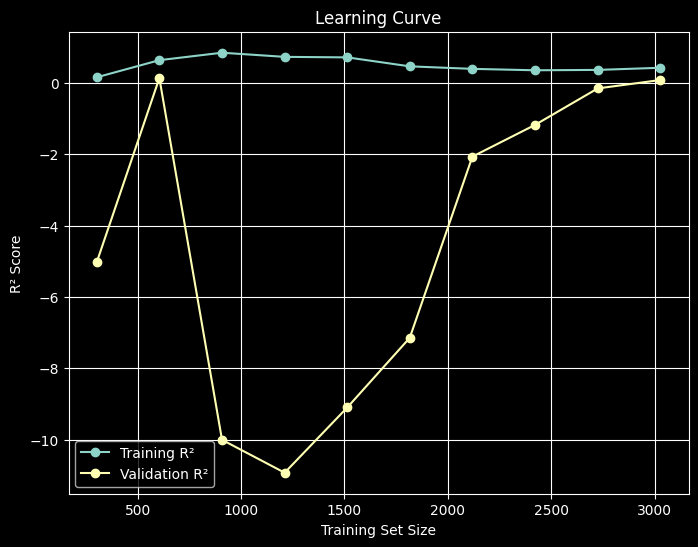

In [12]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt

train_sizes, train_scores, test_scores = learning_curve(
    model, X, y, cv=5, scoring='r2', train_sizes=np.linspace(0.1, 1.0, 10)
)

train_scores_mean = np.mean(train_scores, axis=1)
test_scores_mean = np.mean(test_scores, axis=1)

plt.figure(figsize=(8, 6))
plt.plot(train_sizes, train_scores_mean, 'o-', label='Training R²')
plt.plot(train_sizes, test_scores_mean, 'o-', label='Validation R²')
plt.xlabel('Training Set Size')
plt.ylabel('R² Score')
plt.title('Learning Curve')
plt.legend()
plt.grid(True)
plt.show()

## Feature Engeneering


In [6]:
# create number of days since introduction feature
df["days_since_introduction"] = (
    df["observation_date"] - df["date_of_introduction"]
).dt.days

# Initial Growth Potential
df["initial_growth_potential"] = df["initial_female_count"] * df["leaf_area_cm2"]

#### Linear Regression with Feature Engineering


In [7]:
with mlflow.start_run(run_name="Linear Regression with Feature Engineering"):
    mlflow.sklearn.autolog()

    features = [
        "initial_female_count",
        "leaf_area_cm2",
        "population_density",
        "days_since_introduction",
        "initial_growth_potential",
    ]
    target = "cumulative_mite_count"

    X = df[features]
    y = df[target]

    # --- 2. Split Data into Training and Testing Sets ---
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    # --- 3. Create and Train the Linear Regression Model ---
    model = LinearRegression()
    model.fit(X_train, y_train)
    # --- 4. Make Predictions and Evaluate the Model ---
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # --- 5. Print the Results ---
    print("--- Feature introdused Linear Regression Model Performance ---")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"R-squared (R²): {r2:.4f}")

    mlflow.sklearn.autolog(disable=True)

2025/07/30 12:18:20 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\mlflow\types\utils.py:452: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details."
2025/07/30 12:18:20 WARNING mlflow.utils.autologging_utils: MLflow autologging encountered a warning: "e:\.UWU EDUCATION\spider reseach\cod

--- Feature introdused Linear Regression Model Performance ---
Mean Absolute Error (MAE): 59.2000
Mean Squared Error (MSE): 6090.8817
Root Mean Squared Error (RMSE): 78.0441
R-squared (R²): 0.6929


Feature Importance: {'initial_female_count': np.float64(14.776375673804248), 'leaf_area_cm2': np.float64(22.421735329717702), 'population_density': np.float64(13.347176026638246), 'days_since_introduction': np.float64(13.840216651089374), 'initial_growth_potential': np.float64(-1.3761190860632944)}


C:\Users\kprad\AppData\Local\Temp\ipykernel_12900\837191572.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=feature_importances['Importance'], y=feature_importances['Feature'], palette='viridis')


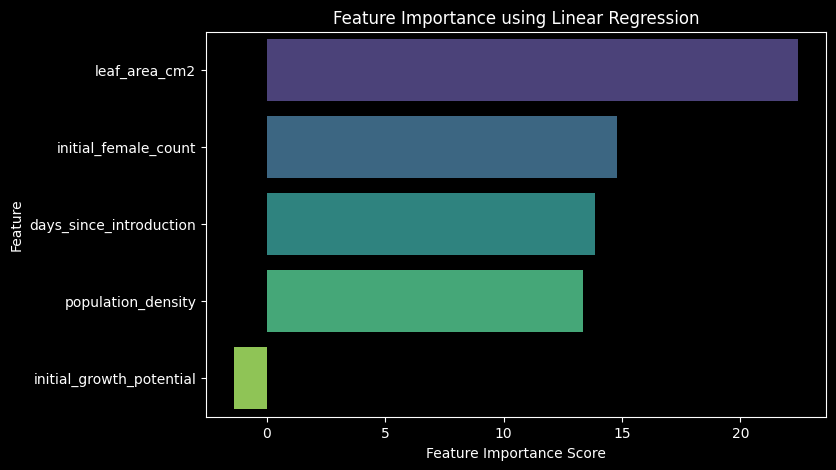

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Model Coefficients
print("Feature Importance:", dict(zip(X.columns, model.coef_)))

# Extract Feature Importances from Linear Regression Coefficients
feature_importances = pd.DataFrame(
    {"Feature": X.columns, "Importance": model.coef_}
).sort_values(by="Importance", ascending=False)

# Plot Feature Importance
plt.figure(figsize=(8, 5))
sns.barplot(
    x=feature_importances["Importance"],
    y=feature_importances["Feature"],
    palette="viridis",
)
plt.xlabel("Feature Importance Score")
plt.ylabel("Feature")
plt.title("Feature Importance using Linear Regression")
plt.show()

### Adding plolynominal features


#### Polynomial Regression for Non-Linear Relationships


In [ ]:
from sklearn.preprocessing import PolynomialFeatures

with mlflow.start_run(run_name="Polynomial Regression"):
    mlflow.sklearn.autolog()

    features = [
        "initial_female_count",
        "leaf_area_cm2",
        "population_density",
        "days_since_introduction",
        "initial_growth_potential",
    ]
    target = "cumulative_mite_count"

    X = df[features]
    y = df[target]

    poly = PolynomialFeatures(degree=3, include_bias=False)
    X_poly = poly.fit_transform(X)

    # --- 2. Split Data into Training and Testing Sets ---
    X_train, X_test, y_train, y_test = train_test_split(
        X_poly, y, test_size=0.2, random_state=42
    )

    # --- 3. Create and Train the Linear Regression Model ---
    model = LinearRegression()
    model.fit(X_train, y_train)
    # --- 4. Make Predictions and Evaluate the Model ---
    y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # --- 5. Print the Results ---
    print("--- Polynominal Feature introdused Linear Regression Model Performance ---")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"R-squared (R²): {r2:.4f}")

    mlflow.sklearn.autolog(disable=True)

--- Polynominal Feature introdused Linear Regression Model Performance ---
Mean Absolute Error (MAE): 35.5555
Mean Squared Error (MSE): 3396.0276
Root Mean Squared Error (RMSE): 58.2754
R-squared (R²): 0.8288


using StandardScaler


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

with mlflow.start_run(run_name="Polynomial Regression with Scaling"):
    mlflow.sklearn.autolog()

    features = [
        "initial_female_count",
        "leaf_area_cm2",
        "population_density",
        "days_since_introduction",
        "initial_growth_potential",
    ]
    target = "cumulative_mite_count"

    X = df[features]
    y = df[target]

    poly = PolynomialFeatures(degree=3, include_bias=False)
    X_poly = poly.fit_transform(X)

    # --- 2. Split Data into Training and Testing Sets ---
    X_train, X_test, y_train, y_test = train_test_split(
        X_poly, y, test_size=0.2, random_state=42
    )

    # Create a scaler and fit it ONLY on the training data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    # Transform the test data using the FITTED scaler
    X_test_scaled = scaler.transform(X_test)

    # --- 3. Create and Train the Linear Regression Model ---
    model = LinearRegression()
    model.fit(X_train_scaled, y_train)
    # --- 4. Make Predictions and Evaluate the Model ---
    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # --- 5. Print the Results ---
    print("--- Polynominal Feature introdused Linear Regression Model Performance ---")
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"R-squared (R²): {r2:.4f}")

    mlflow.sklearn.autolog(disable=True)

--- Polynominal Feature introdused Linear Regression Model Performance ---
Mean Absolute Error (MAE): 35.1889
Mean Squared Error (MSE): 3361.5288
Root Mean Squared Error (RMSE): 57.9787
R-squared (R²): 0.8305


#### Polynomial Regression with Logarithmic Transformation


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
import numpy as np

with mlflow.start_run(run_name="Polynomial Regression with Log Transformation"):
    mlflow.sklearn.autolog()

    df_transformed = df.copy()

    # List of skewed features to transform
    skewed_features = ["initial_growth_potential", "days_since_introduction"]

    # Apply log transformation
    for feat in skewed_features:
        df_transformed[feat] = np.log1p(df_transformed[feat])

    features = [
        "initial_female_count",
        "leaf_area_cm2",
        "population_density",
        "days_since_introduction",
        "initial_growth_potential",
    ]
    target = "cumulative_mite_count"

    X = df_transformed[features]
    y = np.log1p(df["cumulative_mite_count"])

    poly = PolynomialFeatures(degree=3, include_bias=False)
    X_poly = poly.fit_transform(X)

    # --- 2. Split Data into Training and Testing Sets ---
    X_train, X_test, y_train, y_test = train_test_split(
        X_poly, y, test_size=0.2, random_state=42
    )

    # Create a scaler and fit it ONLY on the training data
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)

    # Transform the test data using the FITTED scaler
    X_test_scaled = scaler.transform(X_test)

    # --- 3. Create and Train the Linear Regression Model ---
    model = LinearRegression()
    model.fit(X_train_scaled, y_train)
    # --- 4. Make Predictions and Evaluate the Model ---
    y_pred = model.predict(X_test_scaled)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # --- 5. Print the Results ---
    print(
        "--- Polynominal Feature introdused Linear Regression Model Performance  log transformed---"
    )
    print(f"Mean Absolute Error (MAE): {mae:.4f}")
    print(f"Mean Squared Error (MSE): {mse:.4f}")
    print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
    print(f"R-squared (R²): {r2:.4f}")

    mlflow.sklearn.autolog(disable=True)

--- Polynominal Feature introdused Linear Regression Model Performance  log transformed---
Mean Absolute Error (MAE): 0.3367
Mean Squared Error (MSE): 0.3730
Root Mean Squared Error (RMSE): 0.6107
R-squared (R²): 0.8393


C:\Users\kprad\AppData\Local\Temp\ipykernel_12900\323157199.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Coefficient', y='Feature Index', data=coef_df, palette='viridis')


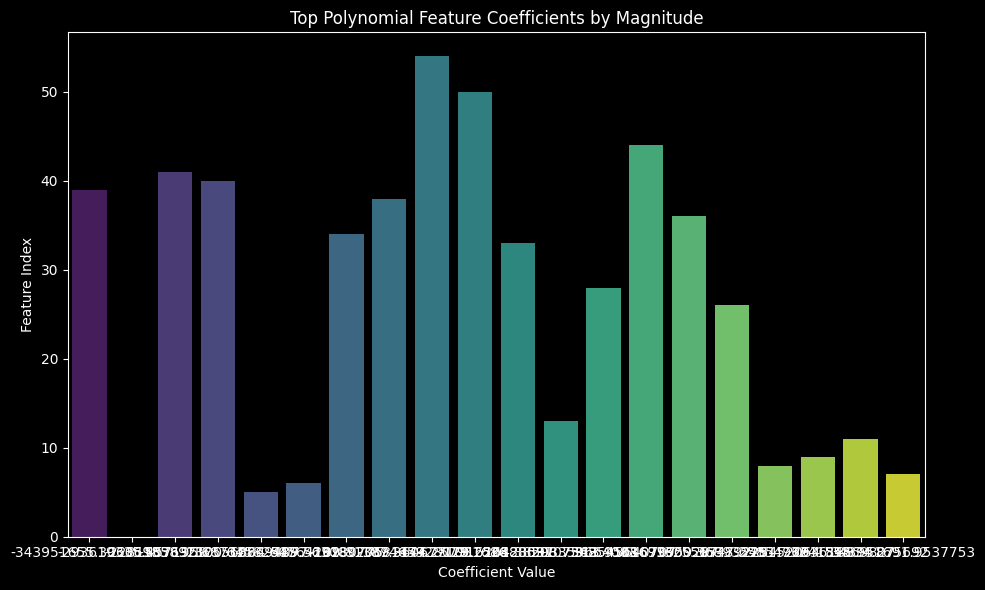

Note: Original features have been transformed into polynomial features.
Original features were: ['initial_female_count', 'leaf_area_cm2', 'population_density', 'days_since_introduction', 'initial_growth_potential']


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# For polynomial models, we can't directly map coefficients to original features
# because there are interactions and higher powers
# Instead, we can show the top coefficients by magnitude

# Get coefficients and their absolute values
coeffs = model.coef_
abs_coeffs = np.abs(coeffs)

# Get indices of top N coefficients by magnitude
top_n = min(20, len(coeffs))  # Show at most 20 features
top_indices = np.argsort(abs_coeffs)[-top_n:]

# Create dataframe for plotting
coef_df = pd.DataFrame(
    {"Feature Index": top_indices, "Coefficient": coeffs[top_indices]}
).sort_values("Coefficient", ascending=False)

# Plot top coefficients
plt.figure(figsize=(10, 6))
sns.barplot(x="Coefficient", y="Feature Index", data=coef_df, palette="viridis")
plt.title("Top Polynomial Feature Coefficients by Magnitude")
plt.xlabel("Coefficient Value")
plt.ylabel("Feature Index")
plt.tight_layout()
plt.show()

# Print original feature importance (for reference only)
print("Note: Original features have been transformed into polynomial features.")
print("Original features were:", features)

In [ ]:
# Assuming 'poly' is your fitted PolynomialFeatures object and 'model' is your trained LinearRegression model

# Get the feature names generated by PolynomialFeatures
poly_feature_names = poly.get_feature_names_out(features)

# Create a DataFrame of the coefficients
df_coeffs = pd.DataFrame({"Feature": poly_feature_names, "Coefficient": model.coef_})

# Sort the coefficients by their absolute value to see the most impactful ones
df_coeffs["Abs_Coefficient"] = df_coeffs["Coefficient"].abs()
df_coeffs = df_coeffs.sort_values(by="Abs_Coefficient", ascending=False)

print("--- Top 10 Most Impactful Features (from Coefficients) ---")
print(df_coeffs.head(10))

--- Top 10 Most Impactful Features (from Coefficients) ---
                                              Feature   Coefficient  \
7             initial_female_count population_density  3.439517e+08   
39                 leaf_area_cm2 population_density^2 -3.439517e+08   
0                                initial_female_count -2.936193e+08   
11                   leaf_area_cm2 population_density  2.936188e+08   
9       initial_female_count initial_growth_potential  2.281521e+08   
41  leaf_area_cm2 population_density initial_growt... -2.281508e+08   
8        initial_female_count days_since_introduction  1.538923e+08   
40  leaf_area_cm2 population_density days_since_in... -1.538921e+08   
5                              initial_female_count^2 -1.325569e+08   
26  initial_female_count leaf_area_cm2 population_...  1.325567e+08   

    Abs_Coefficient  
7      3.439517e+08  
39     3.439517e+08  
0      2.936193e+08  
11     2.936188e+08  
9      2.281521e+08  
41     2.281508e+08  
8    

e:\.UWU EDUCATION\spider reseach\code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Using 3028 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.
100%|██████████| 758/758 [29:57<00:00,  2.37s/it]  



--- SHAP Summary Plot ---


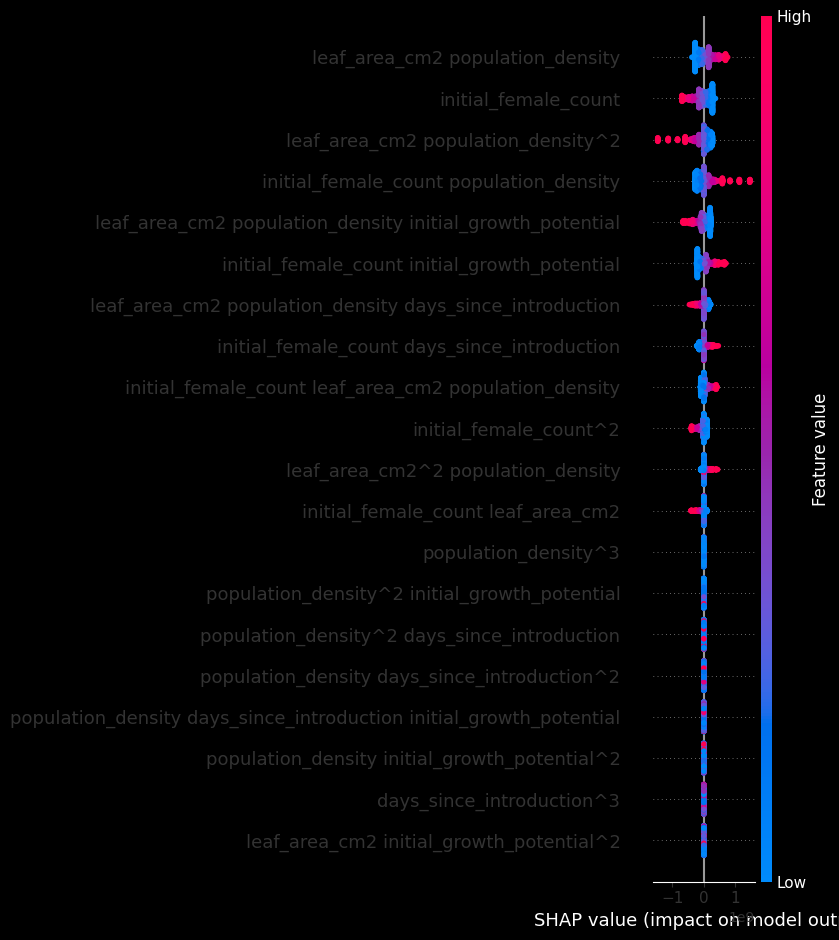

In [14]:
import shap

# --- Prerequisite: Your Final Model ---
# Ensure you have your final trained model ('model')
# and your scaled training and testing data (X_train_scaled, X_test_scaled)
# Note: SHAP works best on scaled data for this type of explainer.

# 1. Create a SHAP Explainer
# We use KernelExplainer, which is model-agnostic. We give it the model's predict function
# and a summary of the training data (a "background" dataset) to learn from.
explainer = shap.KernelExplainer(model.predict, X_train_scaled)

# 2. Calculate SHAP values for the test set (this can take a moment)
shap_values = explainer.shap_values(X_test_scaled)

# 3. Create the Summary Plot
# This is the most powerful SHAP visualization.
print("\n--- SHAP Summary Plot ---")
shap.summary_plot(shap_values, X_test_scaled, feature_names=poly_feature_names)

In [ ]:
from sklearn.metrics import mean_squared_error

y_pred = model.predict(X_test_scaled)
y_pred_train = model.predict(X_train_scaled)
rmse_train = mean_squared_error(y_train, y_pred_train)
rmse_test = mean_squared_error(y_test, y_pred)

r2_score_test = r2_score(y_test, y_pred)
r2_score_train = r2_score(y_train, y_pred_train)

print(f"Train RMSE: {rmse_train:.4f}, Test RMSE: {rmse_test:.4f}")
print(f"Train R²: {r2_score_train:.4f}, Test R²: {r2_score_test:.4f}")

Train RMSE: 0.2284, Test RMSE: 0.3730
Train R²: 0.9045, Test R²: 0.8393
